<a href="https://colab.research.google.com/github/geshtalbt/my_cv_scratch-notebook-jyputer/blob/main/my_cv_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практика 2. Машинное зрение с нуля: учим сеть «видеть»

---

### Цель работы
Собрать и обучить **свёрточную нейронную сеть (CNN)** с нуля и своими глазами увидеть разницу между моделью со случайными весами и обученной моделью.

### Что вы сможете после этой практики
1. Объяснить, что изображение для компьютера — это просто матрица чисел.
2. Собрать CNN из слоёв `Conv2d → BatchNorm → ReLU → MaxPool` и понять, зачем нужен каждый.
3. Обучить модель, снять метрики (accuracy, loss, матрица ошибок) и **защитить результат цифрами**.
4. Найти классы, которые сеть путает, и объяснить почему.

### Как устроен ноутбук
| Этап | Что происходит |
|---|---|
| 1 | Загрузка данных, смотрим, как выглядит датасет |
| 2 | **ДО обучения** — сеть со случайными весами угадывает (~10%) |
| 3 | Обучение — пишем свой цикл обучения на PyTorch |
| 4 | **ПОСЛЕ обучения** — accuracy, кривые обучения, матрица ошибок, ошибки модели |
| 5 | Выводы + домашнее задание |


In [ ]:
!pip install -q torch torchvision scikit-learn matplotlib

In [ ]:
# 1. Импорт библиотек
import time
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Версия PyTorch:", torch.__version__)
print("MPS встроен:", torch.backends.mps.is_built())
print("MPS доступен:", torch.backends.mps.is_available())

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

print("Устройство:", DEVICE)

# фиксируем случайность — чтобы результаты можно было воспроизвести
random.seed(42); np.random.seed(42); torch.manual_seed(42)

Версия PyTorch: 2.14.0
MPS встроен: True
MPS доступен: True
Устройство: mps


## 🔧 БЛОК НАСТРОЕК — это вы будете менять в домашнем задании

`DATASET` — какой датасет берём:
* `"fashion"` — Fashion-MNIST, 10 классов одежды, ч/б 28×28 (быстро, ~26 МБ)
* `"digits"` — MNIST, рукописные цифры 0–9 (ещё быстрее)
* `"cifar"` — CIFAR-10, цветные фото 32×32 (самолёт, кошка, корабль…) — тяжелее, но интереснее

In [ ]:
# ==========================================
# НАСТРОЙКИ ЭКСПЕРИМЕНТА
# ==========================================
DATASET      = "cifar"   # "fashion" | "digits" | "cifar"
TRAIN_SIZE   = 10000       # сколько примеров берём для обучения (из 60000)
TEST_SIZE    = 2000        # сколько примеров для проверки (из 10000)
BATCH_SIZE   = 128
EPOCHS       = 16
LR           = 1e-3         # learning rate — скорость обучения
CHANNELS     = 32          # «ширина» сети: сколько фильтров в первом свёрточном слое

DATA_DIR = "./data"
print(f"Датасет: {DATASET} | train: {TRAIN_SIZE} | epochs: {EPOCHS}")

Датасет: cifar | train: 10000 | epochs: 16


## Этап 1. Данные: как изображение выглядит «изнутри»

In [ ]:

# ==========================================
# ЗАГРУЗКА ДАННЫХ
# ==========================================

SETTINGS = {
    "fashion": (datasets.FashionMNIST, (0.5,), (0.5,)),
    "digits":  (datasets.MNIST,        (0.5,), (0.5,)),
    "cifar":   (datasets.CIFAR10,      (0.5,0.5,0.5), (0.5,0.5,0.5)),
}

DatasetClass, mean, std = SETTINGS[DATASET]

# Преобразования для обучающих изображений
if DATASET == "cifar":
    train_transform = transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])
else:
    train_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])

# Преобразования для тестовых изображений — без аугментации
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

# Загружаем два набора данных с разными преобразованиями
train_full = DatasetClass(
    DATA_DIR,
    train=True,
    download=True,
    transform=train_transform
)

test_full = DatasetClass(
    DATA_DIR,
    train=False,
    download=True,
    transform=test_transform
)

train_ds = Subset(train_full, range(TRAIN_SIZE))
test_ds  = Subset(test_full, range(TEST_SIZE))

train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
test_dl  = DataLoader(test_ds, batch_size=256, shuffle=False)

CLASS_NAMES = train_full.classes
NUM_CLASSES = len(CLASS_NAMES)
IN_CHANNELS = 1 if DATASET != "cifar" else 3
IMG_SIZE = train_ds[0][0].shape[-1]

print(f"Классов: {NUM_CLASSES} | каналов: {IN_CHANNELS} | размер: {IMG_SIZE}x{IMG_SIZE}")
print(f"Обучение: {len(train_ds)} картинок | Проверка: {len(test_ds)} картинок")
print("Названия классов:", CLASS_NAMES)


Классов: 10 | каналов: 3 | размер: 32x32
Обучение: 10000 картинок | Проверка: 2000 картинок
Названия классов: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [ ]:
# Как выглядит один пример
x, y = train_ds[0]
print("Форма тензора (C, H, W):", tuple(x.shape))
print("Метка (номер класса):", y, "->", CLASS_NAMES[y])
print("Минимум / максимум пикселя:", round(float(x.min()), 3), "/", round(float(x.max()), 3))
print()
print("Фрагмент картинки 8x8 пикселей — именно такие ЧИСЛА видит нейросеть:")
print(np.round(x[0, 10:18, 10:18].numpy(), 2))

Форма тензора (C, H, W): (3, 32, 32)
Метка (номер класса): 6 -> frog
Минимум / максимум пикселя: -1.0 / 1.0

Фрагмент картинки 8x8 пикселей — именно такие ЧИСЛА видит нейросеть:
[[ 0.09  0.05  0.11 -0.05 -0.37 -0.24 -0.29 -0.23]
 [-0.08 -0.19  0.02 -0.06 -0.13  0.15  0.07  0.28]
 [-0.34 -0.31 -0.15 -0.21  0.08  0.67  0.4   0.5 ]
 [-0.44 -0.36 -0.34 -0.16  0.29  0.8   0.44  0.5 ]
 [-0.3  -0.18 -0.25  0.01  0.51  0.45  0.14  0.59]
 [-0.48 -0.31 -0.11  0.43  0.73  0.08  0.27  0.62]
 [-0.34 -0.12  0.28  0.75  0.62  0.14  0.54  0.6 ]
 [-0.15  0.13  0.65  0.95  0.37  0.37  0.73  0.77]]


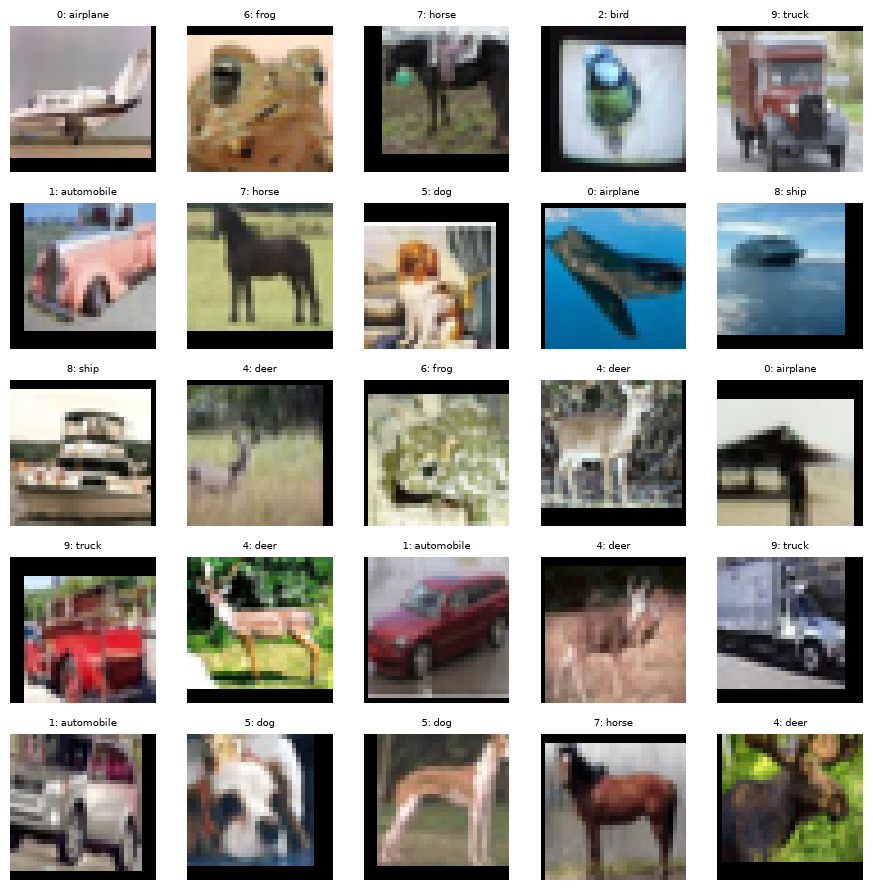

In [ ]:
# Смотрим 25 случайных картинок с подписями
fig, axes = plt.subplots(5, 5, figsize=(9, 9))
idxs = random.sample(range(len(train_ds)), 25)
for ax, i in zip(axes.ravel(), idxs):
    x, y = train_ds[i]
    img = x.squeeze(0).numpy() if IN_CHANNELS == 1 else x.numpy().transpose(1, 2, 0)
    if img.ndim == 3:
        img = img * 0.5 + 0.5          # возвращаем из нормализации в 0..1
    ax.imshow(img, cmap="gray" if IN_CHANNELS == 1 else None)
    ax.set_title(f"{y}: {CLASS_NAMES[y]}", fontsize=7)
    ax.axis("off")
plt.tight_layout(); plt.show()

## Модель: маленькая свёрточная сеть

```
Вход [1, 28, 28]
  └─ Conv2d(32)  → ищет простые признаки: края, углы, пятна
  └─ BatchNorm   → стабилизирует обучение
  └─ ReLU        → нелинейность (без неё сеть = один линейный слой)
  └─ MaxPool 2x2 → уменьшает картинку в 2 раза, оставляет «самое важное»
  └─ Conv2d(64)  → из простых признаков собирает сложные: рукав, подошва, карман
  └─ MaxPool 2x2
  └─ Flatten → Linear(128) → Dropout → Linear(10)  = «головка» классификатора
```

**Свёртка** — это маленькое «окошко» (ядро 3×3), которое скользит по картинке и в каждой точке считает взвешенную сумму. Веса окна сеть **учит сама**.

In [ ]:

class TinyCNN(nn.Module):
    def __init__(self, in_channels=1, num_classes=10, channels=32, img_size=28):
        super().__init__()

        # После трёх MaxPool2d размер изображения уменьшается в 8 раз
        s = img_size // 8

        self.features = nn.Sequential(
            # Первый блок
            nn.Conv2d(in_channels, channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(channels),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Второй блок
            nn.Conv2d(channels, channels * 2, kernel_size=3, padding=1),
            nn.BatchNorm2d(channels * 2),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Третий блок — новый
            nn.Conv2d(channels * 2, channels * 4, kernel_size=3, padding=1),
            nn.BatchNorm2d(channels * 4),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(channels * 4 * s * s, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.head(self.features(x))


model = TinyCNN(IN_CHANNELS, NUM_CLASSES, CHANNELS, IMG_SIZE).to(DEVICE)

n_params = sum(p.numel() for p in model.parameters())

print(model)
print(f"\nВсего параметров: {n_params:,} (~{n_params / 1e6:.2f} млн)")


TinyCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=256, bias=True)
    (2

## Этап 2. ДО обучения: что умеет сеть со случайными весами?

Запускаем **ещё не обученную** модель на тестовых данных. Угадывать 1 из 10 классов наугад = 10%. Посмотрим, что покажет сеть.

In [ ]:
# ==========================================
# ФУНКЦИИ ОБУЧЕНИЯ И ПРОВЕРКИ
# ==========================================
def evaluate(model, dataloader):
    # Возвращает accuracy, список настоящих и предсказанных меток.
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for x, y in dataloader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            pred = model(x).argmax(dim=1)
            y_true += y.tolist(); y_pred += pred.tolist()
    return accuracy_score(y_true, y_pred), y_true, y_pred

def predict_one(model, x):
    # Предсказание + уверенность для одной картинки.
    model.eval()
    with torch.no_grad():
        logits = model(x.unsqueeze(0).to(DEVICE))[0]
        probs = logits.softmax(dim=0)
        cls = int(probs.argmax())
    return cls, float(probs[cls]), probs.cpu().numpy()

def show_samples(model, dataset, n=12, seed=7, title=""):
    # Сетка картинок с предсказаниями: зелёная рамка — верно, красная — ошибка.
    model.eval()
    fig, axes = plt.subplots(2, n // 2, figsize=(n * 1.15, 3.0))
    for ax, i in zip(axes.ravel(), random.Random(seed).sample(range(len(dataset)), n)):
        x, y = dataset[i]
        cls, conf, _ = predict_one(model, x)
        img = x.squeeze(0).numpy() if IN_CHANNELS == 1 else x.numpy().transpose(1, 2, 0)
        if img.ndim == 3:
            img = img * 0.5 + 0.5
        ax.imshow(img, cmap="gray" if IN_CHANNELS == 1 else None)
        ax.set_title(f"→ {CLASS_NAMES[cls][:12]}\n{conf:.0%}", fontsize=7,
                     color="green" if cls == y else "red")
        ax.set_xlabel(f"truth: {CLASS_NAMES[y][:12]}", fontsize=6)
        ax.axis("off")
        for s in ax.spines.values():
            s.set_edgecolor("green" if cls == y else "red"); s.set_linewidth(2)
    if title: fig.suptitle(title, fontsize=12)
    plt.tight_layout(); plt.show()

# --- ЭТАП 2: проверка ДО обучения ---
acc_before, _, _ = evaluate(model, test_dl)
print("=" * 60)
print("ЭТАП 2: МОДЕЛЬ ДО ОБУЧЕНИЯ (веса случайные)")
print("=" * 60)
print(f"Accuracy: {acc_before*100:.2f}%   (случайное угадывание = {100/NUM_CLASSES:.1f}%)")

ЭТАП 2: МОДЕЛЬ ДО ОБУЧЕНИЯ (веса случайные)
Accuracy: 10.30%   (случайное угадывание = 10.0%)


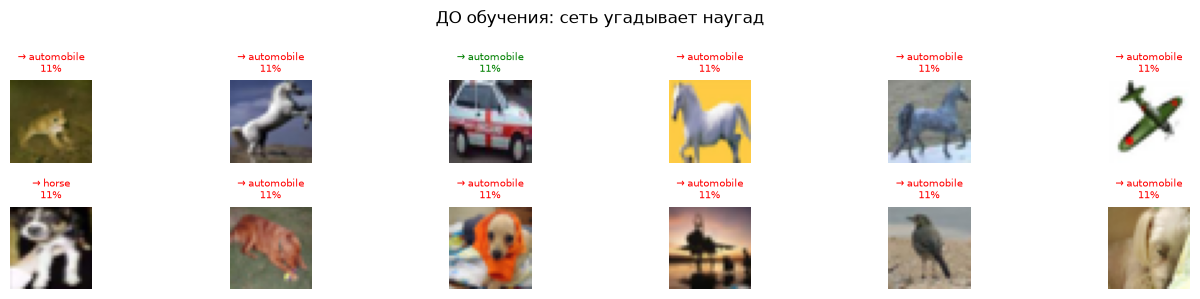

In [ ]:
show_samples(model, test_ds, n=12, seed=7, title="ДО обучения: сеть угадывает наугад")

## Этап 3. Обучение: цикл из четырёх строк

Каждый шаг (batch) делает одно и то же:

```python
optimizer.zero_grad()      # 1. обнуляем старые градиенты
loss = criterion(out, y)   # 2. считаем, насколько ошиблись
loss.backward()            # 3. считаем градиенты (кто виноват)
optimizer.step()           # 4. чуть-чуть меняем веса против ошибки
```

Это **и есть** машинное обучение. Всё остальное — обвязка.

In [ ]:
# ==========================================
# ОБУЧЕНИЕ
# ==========================================
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode="max",
    factor=0.5,
    patience=3,
    min_lr=1e-5
)

history = {"train_loss": [], "train_acc": [], "test_acc": []}
t0 = time.time()

best_accuracy = 0.0
patience = 7
epochs_without_improvement = 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss, n_samples, correct = 0.0, 0, 0
    for x, y in train_dl:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)
        n_samples  += x.size(0)
        correct    += (out.argmax(1) == y).sum().item()

    train_loss = total_loss / n_samples
    train_acc  = correct / n_samples
    test_acc, _, _ = evaluate(model, test_dl)
    scheduler.step(test_acc)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["test_acc"].append(test_acc)
    print(f"Epoch {epoch:>2}/{EPOCHS} | loss {train_loss:.4f} | "
          f"train acc {train_acc*100:5.2f}% | test acc {test_acc*100:5.2f}%")

    if test_acc > best_accuracy:
        best_accuracy = test_acc
        epochs_without_improvement = 0

        torch.save(model.state_dict(), "best_model.pth")

        print("Лучшая модель сохранена!")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early Stopping: обучение остановлено!")
        break

train_time = time.time() - t0
print(f"\nОбучение заняло {train_time:.1f} секунд на {DEVICE}")

model.load_state_dict(
    torch.load("best_model.pth", map_location=DEVICE)
)

print(f"Лучшая Test Accuracy: {best_accuracy*100:.2f}%")

Epoch  1/16 | loss 1.8179 | train acc 32.59% | test acc 43.40%
Лучшая модель сохранена!
Epoch  2/16 | loss 1.5051 | train acc 43.99% | test acc 50.15%
Лучшая модель сохранена!
Epoch  3/16 | loss 1.3793 | train acc 49.36% | test acc 54.60%
Лучшая модель сохранена!
Epoch  4/16 | loss 1.2907 | train acc 52.88% | test acc 58.15%
Лучшая модель сохранена!
Epoch  5/16 | loss 1.2197 | train acc 56.02% | test acc 55.65%
Epoch  6/16 | loss 1.1489 | train acc 58.77% | test acc 61.35%
Лучшая модель сохранена!
Epoch  7/16 | loss 1.1135 | train acc 59.81% | test acc 63.10%
Лучшая модель сохранена!
Epoch  8/16 | loss 1.0625 | train acc 62.16% | test acc 61.00%
Epoch  9/16 | loss 1.0383 | train acc 62.33% | test acc 63.40%
Лучшая модель сохранена!
Epoch 10/16 | loss 1.0033 | train acc 64.42% | test acc 63.85%
Лучшая модель сохранена!
Epoch 11/16 | loss 0.9629 | train acc 65.37% | test acc 69.20%
Лучшая модель сохранена!
Epoch 12/16 | loss 0.9581 | train acc 65.64% | test acc 68.15%
Epoch 13/16 | loss 

## Этап 4. ПОСЛЕ обучения: метрики и разбор ошибок

In [ ]:
acc_after, y_true, y_pred = evaluate(model, test_dl)
print("=" * 60)
print("ЭТАП 4: МОДЕЛЬ ПОСЛЕ ОБУЧЕНИЯ")
print("=" * 60)
print(f"Accuracy ДО обучения:  {acc_before*100:6.2f}%")
print(f"Accuracy ПОСЛЕ:        {acc_after*100:6.2f}%")
print(f"Прирост:               {(acc_after-acc_before)*100:+6.2f} п.п. за {train_time:.0f} c")

ЭТАП 4: МОДЕЛЬ ПОСЛЕ ОБУЧЕНИЯ
Accuracy ДО обучения:   10.30%
Accuracy ПОСЛЕ:         70.45%
Прирост:               +60.15 п.п. за 25 c


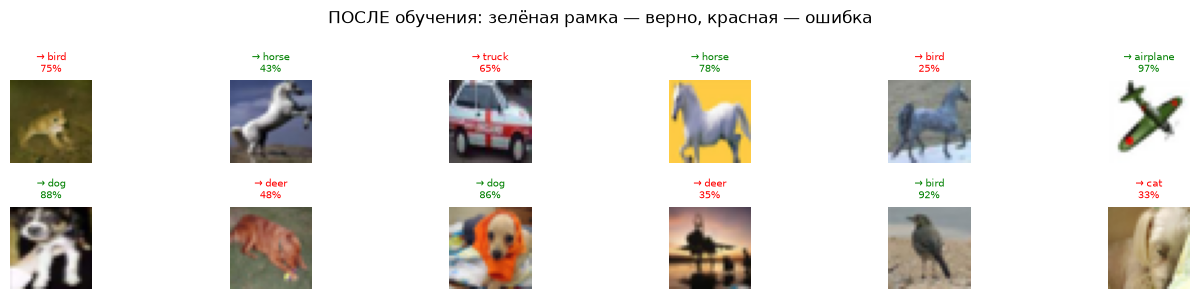

In [ ]:
show_samples(model, test_ds, n=12, seed=7, title="ПОСЛЕ обучения: зелёная рамка — верно, красная — ошибка")

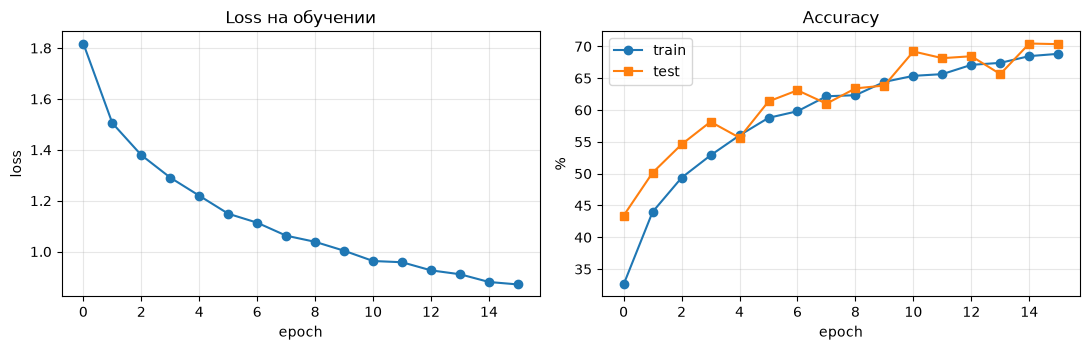

Как читать график:
 • loss падает, обе accuracy растут  → обучение идёт нормально
 • train растёт, test остановился    → переобучение (нужно больше данных / Dropout / аугментации)
 • loss скачет                       → learning rate слишком большой


In [ ]:
# Кривые обучения — главный инструмент диагностики
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(history["train_loss"], marker="o")
ax[0].set_title("Loss на обучении"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].grid(alpha=.3)
ax[1].plot([a*100 for a in history["train_acc"]], marker="o", label="train")
ax[1].plot([a*100 for a in history["test_acc"]],  marker="s", label="test")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("%"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print("Как читать график:")
print(" • loss падает, обе accuracy растут  → обучение идёт нормально")
print(" • train растёт, test остановился    → переобучение (нужно больше данных / Dropout / аугментации)")
print(" • loss скачет                       → learning rate слишком большой")

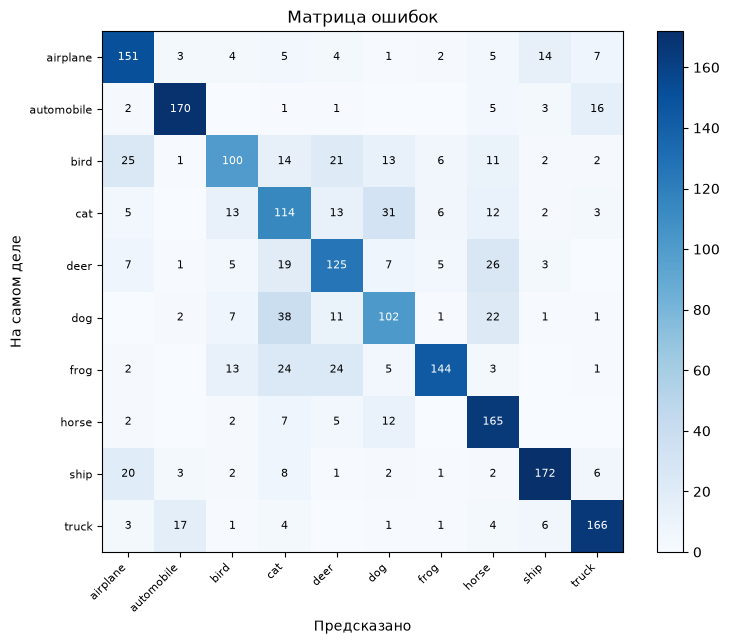

In [ ]:
# Матрица ошибок: строка = настоящий класс, столбец = что предсказала сеть
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
plt.figure(figsize=(8, 6.5))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if cm[i, j]:
            plt.text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right", fontsize=8)
plt.yticks(range(NUM_CLASSES), CLASS_NAMES, fontsize=8)
plt.xlabel("Предсказано"); plt.ylabel("На самом деле")
plt.title("Матрица ошибок"); plt.tight_layout(); plt.show()

In [ ]:
# Какие классы сеть путает сильнее всего?
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3))

per_class = cm.diagonal() / cm.sum(axis=1).clip(min=1)
order = np.argsort(per_class)
print("ХУДШИЕ классы (их сеть распознаёт хуже всего):")
for i in order[:3]:
    wrong = np.argsort(-cm[i])[1]        # самый частый неверный ответ
    print(f"  {CLASS_NAMES[i]:<28} accuracy {per_class[i]*100:5.1f}%  | чаще всего путает с '{CLASS_NAMES[wrong]}'")
print("\nЛУЧШИЕ классы:")
for i in order[-3:][::-1]:
    print(f"  {CLASS_NAMES[i]:<28} accuracy {per_class[i]*100:5.1f}%")

              precision    recall  f1-score   support

    airplane      0.696     0.770     0.731       196
  automobile      0.863     0.859     0.861       198
        bird      0.680     0.513     0.585       195
         cat      0.487     0.573     0.527       199
        deer      0.610     0.631     0.620       198
         dog      0.586     0.551     0.568       185
        frog      0.867     0.667     0.754       216
       horse      0.647     0.855     0.737       193
        ship      0.847     0.793     0.819       217
       truck      0.822     0.818     0.820       203

    accuracy                          0.705      2000
   macro avg      0.711     0.703     0.702      2000
weighted avg      0.714     0.705     0.705      2000

ХУДШИЕ классы (их сеть распознаёт хуже всего):
  bird                         accuracy  51.3%  | чаще всего путает с 'airplane'
  dog                          accuracy  55.1%  | чаще всего путает с 'cat'
  cat                          accura

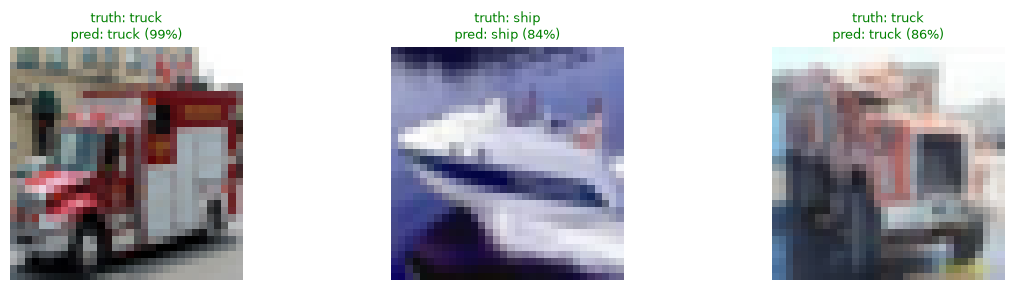

Если уверенность высокая, а ответ неверный — это 'уверенная ошибка':
такую модель нельзя пускать в продакшн без порога доверия (confidence threshold).


In [ ]:
# Уверенность модели: насколько она «сомневается» в ответе
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, i in zip(axes, random.Random(3).sample(range(len(test_ds)), 3)):
    x, y = test_ds[i]
    cls, conf, probs = predict_one(model, x)
    img = x.squeeze(0).numpy() if IN_CHANNELS == 1 else x.numpy().transpose(1, 2, 0)
    if img.ndim == 3: img = img * 0.5 + 0.5
    ax.imshow(img, cmap="gray" if IN_CHANNELS == 1 else None)
    ax.set_title(f"truth: {CLASS_NAMES[y]}\npred: {CLASS_NAMES[cls]} ({conf:.0%})",
                 fontsize=9, color="green" if cls == y else "red")
    ax.axis("off")
plt.tight_layout(); plt.show()

print("Если уверенность высокая, а ответ неверный — это 'уверенная ошибка':")
print("такую модель нельзя пускать в продакшн без порога доверия (confidence threshold).")

In [ ]:
# Выводы (заполните своими цифрами)

1. До обучения сеть со случайными весами дала accuracy `12.90%`, что примерно равно случайному угадыванию `10 %`.
2. После `8` эпох обучения accuracy выросла до `89.10%`, loss уменьшился с `0.71 до 0.21`.
4. Хуже всего сеть распознаёт класс `coat`, путая его с `shirt`, потому что `произошел Class Confusion`.
5. Параметры, которые я менял(а) и что они дали: `ничего не изменял, использовал стандартные значения`.




SyntaxError: invalid syntax (2319290008.py, line 3)

## Домашнее задание

**Задание 1 (обязательное). Свой классификатор.**
Обучите модель на **другом** датасете и получите accuracy не ниже 80%. Варианты:
* **А.** Поменять в настройках `DATASET = "cifar"` (цветные фото) и `IN_CHANNELS` подхватится сам. Подберите `CHANNELS`/`EPOCHS`, чтобы вышло ≥ 65%.
* **Б.** Свой датасет: сфотографировать 3 класса по 30–50 фото (кружка / бутылка / ноутбук), разложить по папкам `data/мой_класс/...` и обучить `ImageFolder`.
    
**Задание 2 (обязательное). Эксперимент с гиперпараметрами.**
Проведите **минимум 4** запуска, меняя по одному параметру, и заполните таблицу:

| № | Что изменил | TRAIN_SIZE | CHANNELS | EPOCHS | LR | Test accuracy | Время, с |
|---|---|---|---|---|---|---|---|
| 1 | базовый запуск | 10000 | 32 | 8 | 1e-3 | | |
| 2 | меньше данных | 2000 | 32 | 8 | 1e-3 | | |
| 3 | шире сеть | 10000 | 64 | 8 | 1e-3 | | |
| 4 | больше эпох | 10000 | 32 | 16 | 1e-3 | | |

Сделайте вывод: **что сильнее всего влияет на качество** в вашем эксперименте.

**Задание 3 (повышенной сложности).** Добавьте в сеть третий свёрточный слой или аугментации (`transforms.RandomHorizontalFlip()`, `transforms.RandomRotation(10)`) и покажите, как изменилась accuracy на тесте.

**Форма отчёта:** ноутбук с выполненными ячейками + таблица экспериментов + 4 вывода своими словами.

In [ ]:
# CIFAR-10: Обучение и улучшение сверточной нейронной сети

### 1. Сохранение лучшей модели и Early Stopping

Во время обучения модели я добавил механизм сохранения лучшей версии модели и Early Stopping. Это позволяет не ждать окончания всех эпох, если качество модели перестало улучшаться.

Если точность на тестовой выборке становится выше предыдущего результата, модель сохраняется в файл `best_model.pth`. Если качество не улучшается в течение определённого количества эпох (`patience`), обучение автоматически останавливается.


if test_acc > best_accuracy:
    best_accuracy = test_acc
    epochs_without_improvement = 0

    torch.save(model.state_dict(), "best_model.pth")

    print("Лучшая модель сохранена!")

else:
    epochs_without_improvement += 1

if epochs_without_improvement >= patience:
    print("Early Stopping: обучение остановлено!")
    break

После завершения обучения загружаем лучшую сохранённую модель:

model.load_state_dict(
    torch.load("best_model.pth", map_location=DEVICE)
)

print(f"Лучшая Test Accuracy: {best_accuracy*100:.2f}%")

### 2. Первый результат обучения

После настройки модели мне удалось добиться точности 73% Test Accuracy.

Использовались следующие параметры:

| Параметр   | Значение |
| ---------- | -------- |
| TRAIN_SIZE | 30000    |
| TEST_SIZE  | 3000     |
| BATCH_SIZE | 128      |
| EPOCHS     | 35       |
| LR         | 1e-3     |
| CHANNELS   | 64       |
| Dropout    | 0.3      |

Дальнейшее обучение практически не улучшало результат, а модель начинала переобучаться.

Чтобы решить эту проблему, я решил добавить `ReduceLROnPlateau`. Это механизм, который автоматически уменьшает Learning Rate, если качество модели перестаёт улучшаться. Благодаря этому обучение может продолжаться более стабильно.

### 3. Добавление ReduceLROnPlateau

Для следующего эксперимента я изменил только размер обучающей и тестовой выборок:

- TRAIN_SIZE: 20000
- TEST_SIZE: 2000

Остальные параметры остались прежними.

В результате модель показала лучший результат на 23-й эпохе:

| Метрика        | Результат |
| -------------- | --------- |
| Loss           | 0.4124    |
| Train Accuracy | 84.86%    |
| Test Accuracy  | 73.15%    |

Несмотря на использование ReduceLROnPlateau, дальнейшее обучение снова приводило к переобучению.

### 4. Добавление аугментации данных

Для улучшения качества модели я решил добавить аугментацию данных (Data Augmentation).

Аугментация позволяет создавать изменённые версии изображений прямо во время обучения. Благодаря этому модель учится распознавать объекты в разных положениях и становится менее зависимой от конкретного расположения объектов на изображении.

Для CIFAR-10 я добавил два преобразования:

1. `RandomCrop(32, padding=4)` — добавляет рамку вокруг изображения и случайным образом выбирает участок размером 32×32. Это позволяет немного смещать изображение.
2. `RandomHorizontalFlip()` — с вероятностью 50% отражает изображение по горизонтали.

Для тестовой выборки аугментация не используется, чтобы результаты проверки оставались объективными.

# ==========================================
# ЗАГРУЗКА ДАННЫХ
# ==========================================

SETTINGS = {
    "fashion": (datasets.FashionMNIST, (0.5,), (0.5,)),
    "digits":  (datasets.MNIST, (0.5,), (0.5,)),
    "cifar":   (datasets.CIFAR10, (0.5, 0.5, 0.5),
                (0.5, 0.5, 0.5)),
}

DatasetClass, mean, std = SETTINGS[DATASET]

# Преобразования для обучающих изображений
if DATASET == "cifar":
    train_transform = transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])
else:
    train_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])

# Преобразования для тестовых изображений
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

# Загружаем наборы данных
train_full = DatasetClass(
    DATA_DIR,
    train=True,
    download=True,
    transform=train_transform
)

test_full = DatasetClass(
    DATA_DIR,
    train=False,
    download=True,
    transform=test_transform
)

train_ds = Subset(train_full, range(TRAIN_SIZE))
test_ds = Subset(test_full, range(TEST_SIZE))

train_dl = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_dl = DataLoader(
    test_ds,
    batch_size=256,
    shuffle=False
)

CLASS_NAMES = train_full.classes
NUM_CLASSES = len(CLASS_NAMES)
IN_CHANNELS = 1 if DATASET != "cifar" else 3
IMG_SIZE = train_ds[0][0].shape[-1]

print(f"Классов: {NUM_CLASSES} | каналов: {IN_CHANNELS} | размер: {IMG_SIZE}x{IMG_SIZE}")
print(f"Обучение: {len(train_ds)} картинок | Проверка: {len(test_ds)} картинок")
print("Названия классов:", CLASS_NAMES)

После обучения на протяжении 33 эпох модель показала следующий результат:

| Метрика        | Результат |
| -------------- | --------- |
| Loss           | 1.0408    |
| Train Accuracy | 61.39%    |
| Test Accuracy  | 72.55%    |

Train Accuracy снизился, потому что модель теперь обучается на более разнообразных и сложных изображениях.

При этом мы решили главную проблему — уменьшили переобучение модели. Теперь она лучше справляется с изображениями, которые отличаются от тех, что использовались при обучении.

### 5. Добавление третьего сверточного блока

Для достижения более высоких результатов я решил увеличить сложность нейронной сети.

Были внесены два основных изменения:

1. Добавлен третий сверточный блок, который позволяет извлекать более сложные признаки изображений.
2. Скрытый слой классификатора увеличен со 128 до 256 нейронов.

class TinyCNN(nn.Module):
    def __init__(
        self,
        in_channels=1,
        num_classes=10,
        channels=32,
        img_size=28
    ):
        super().__init__()

        # После трёх MaxPool2d размер изображения уменьшается в 8 раз
        s = img_size // 8

        self.features = nn.Sequential(
            # Первый блок
            nn.Conv2d(in_channels, channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(channels),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Второй блок
            nn.Conv2d(channels, channels * 2, kernel_size=3, padding=1),
            nn.BatchNorm2d(channels * 2),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Третий блок
            nn.Conv2d(channels * 2, channels * 4, kernel_size=3, padding=1),
            nn.BatchNorm2d(channels * 4),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(channels * 4 * s * s, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.head(self.features(x))


model = TinyCNN(
    IN_CHANNELS,
    NUM_CLASSES,
    CHANNELS,
    IMG_SIZE
).to(DEVICE)

n_params = sum(p.numel() for p in model.parameters())

print(model)
print(f"\nВсего параметров: {n_params:,} (~{n_params / 1e6:.2f} млн)")

После добавления третьего сверточного блока результат значительно улучшился!

Модель показала 81.85% Test Accuracy на 34-й эпохе.

Результаты лучшей эпохи:

| Метрика        | Результат |
| -------------- | --------- |
| Loss           | 0.4673    |
| Train Accuracy | 83.81%    |
| Test Accuracy  | 81.85%    |

Прирост по сравнению с предыдущей моделью составил около +8.7 процентного пункта.

По сравнению с первоначальным результатом необученной модели прирост составил около +70.9 процентного пункта.

### 6. Анализ ошибок модели

После обучения я решил проверить, какие классы модель распознаёт лучше всего, а с какими возникают проблемы.

Худшие результаты:

| Класс | Точность | Основная ошибка   |
| ----- | -------- | ----------------- |
| Cat   | 61.3%    | Путает с Dog      |
| Bird  | 71.3%    | Путает с Airplane |
| Dog   | 75.1%    | Путает с Cat      |

Лучшие результаты:

| Класс      | Точность |
| ---------- | -------- |
| Ship       | 92.2%    |
| Truck      | 90.1%    |
| Automobile | 89.9%    |

Можно заметить, что модели проще распознавать транспортные средства, чем животных. Вероятно, это связано с тем, что некоторые классы животных имеют похожие визуальные признаки.

### 7. Сравнение экспериментов

В заключение я решил провести несколько экспериментов, чтобы определить, какие параметры сильнее всего влияют на качество модели.

| № | Эксперимент    | TRAIN_SIZE | CHANNELS | EPOCHS | LR   | Test Accuracy | Время  |
| - | -------------- | ---------- | -------- | ------ | ---- | ------------- | ------ |
| 1 | Базовый запуск | 10000      | 32       | 8      | 1e-3 | 62.95%        | 11.4 с |
| 2 | Меньше данных  | 2000       | 32       | 8      | 1e-3 | 48.05%        | 3.7 с  |
| 3 | Шире сеть      | 10000      | 64       | 8      | 1e-3 | 61.80%        | 20.4 с |
| 4 | Больше эпох    | 10000      | 32       | 16     | 1e-3 | 69.80%        | 22.4 с |

### 8. Итоговый вывод

Исходя из проведённых экспериментов, я могу сделать несколько выводов:

1. Количество эпох сильно влияет на качество модели. При увеличении количества эпох с 8 до 16 точность выросла с 62.95% до 69.80%.
2. Количество обучающих данных также очень важно. При уменьшении TRAIN_SIZE с 10000 до 2000 точность упала с 62.95% до 48.05%.
3. Увеличение ширины сети не всегда приводит к улучшению результата. В моём эксперименте увеличение CHANNELS с 32 до 64 даже немного снизило точность.

Таким образом, я считаю, что для улучшения качества модели важно найти баланс между количеством данных, сложностью нейронной сети и продолжительностью обучения.

Не рекомендую без необходимости уменьшать TRAIN_SIZE, так как модель начинает значительно хуже распознавать изображения.

Увеличение ширины сети может быть полезно, когда текущей модели не хватает выразительности, однако само по себе оно не гарантирует улучшения результата.

Небольшое техническое замечание: перед сдачей я бы рекомендовал проверить два момента:

- `best_accuracy` у тебя выбирается по `test_acc`. Для корректной оценки модели лучше использовать отдельную validation-выборку для Early Stopping, а тестовую оставить для финальной проверки.
- В выводах сравниваются эксперименты с разными настройками. Поэтому результаты показывают влияние параметров именно в проведённых условиях, а не универсальную зависимость.

Так ноутбук будет не просто содержать код, а показывать последовательность экспериментов, результаты и выводы по каждому изменению.